# Snow depth data workflow

Frankfurt–München · Input snapshot: 16 October 2026

One workflow: **read observations → select primary/backup → screen → locate review candidates → validate and export → report**.

This notebook produces `observations/snow_depth.parquet` for DWD source observations and `observations/railway_snow_depth_initial.parquet` for the initial railway-station selection. The one flagged record retains its current primary under the recorded project decision. Current integration input: `observations/railway_snow_depth_reviewed.parquet`. The existing station mapping is unchanged.

Run the six code cells in order. Requirements: Python 3, pandas, numpy, matplotlib, pyarrow and the accompanying `weather_processing.py` and `snow_depth_review.py`. Outputs are written under this weather directory.

## 1. Setup and rules

SHK_TAG is daily snow depth in cm. The mapped archives specify 06 UTC; retain the observation date and that reference time. A measurement time is not a publication time. Do not expand daily observations into hourly measurements. Zero is valid; a long period without snow is not a stuck sensor.

- Use the primary station when its observation is available; otherwise use the mapped backup at the same UTC hour, or the same compatible observation date for snow depth.
- Convert `-999`, blanks and non-numeric/non-finite values to unavailable values while preserving raw tokens. Historical rows take priority over recent rows, including missing historical values. Same-priority value conflicts are unavailable pending review.
- Preserve finite numeric screening candidates. Thresholds below are project review rules, not DWD quality standards or deletion rules. Quality-code changes alone do not invalidate an observation.
- Report remaining missingness, consecutive gaps, duplicates/conflicts, extreme values, changes, repeated positive values and primary/backup differences. No interpolation or zero filling is used.

Exports contain the study interval and a preceding 48-hour buffer (two observation dates for snow depth). Coverage counts exclude the buffer. No journey targets or model results are used.

In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display

# Set WEATHER_DIR explicitly if this notebook is launched from another directory.
WEATHER_DIR = Path.cwd()
if not (WEATHER_DIR / "station_mapping.json").is_file():
    candidates = [p / "frankfurt_munich/weather" for p in [Path.cwd(), *Path.cwd().parents]]
    WEATHER_DIR = next((p for p in candidates if (p / "station_mapping.json").is_file()), WEATHER_DIR)
WEATHER_DIR = WEATHER_DIR.resolve()
sys.path.insert(0, str(WEATHER_DIR))
from weather_processing import WeatherWorkflow

# Default local package: raw/dwd/. External original ZIPs can be supplied here.
ARCHIVE_DIR = Path(os.environ.get("DWD_WEATHER_ARCHIVE_DIR", str(WEATHER_DIR / "raw/dwd"))).expanduser()
workflow = WeatherWorkflow("SHK_TAG", WEATHER_DIR, ARCHIVE_DIR)
# Optional project screening overrides, before processing:
# workflow.rules["high"] = ...
display(workflow.rule_table())
workflow.show_inputs()

Snow depth: 19 railway stations, 20 DWD stations, 40 hash-matched ZIPs.
Study: 2024-07-01 to 2026-10-01 exclusive; preceding buffer: 48 hours / 2 dates.


,check,value
0,Physical range,negative values flagged; retained (cm)
1,High value,> 50.0 cm
2,Adjacent-time absolute change,> 20.0 cm
3,Primary/backup absolute difference,> 30.0 cm
4,Identical positive run,>= 30 days
5,Zero runs,valid; no stuck-sensor flag


## 2. Read and standardize DWD observations

Verify archive hashes, station IDs, units and time-reference metadata for the retained period. Read the original product TXT files and retain archive/member/line provenance, raw values and quality codes. Resolve archive overlaps and construct the complete DWD time grid. Save monthly station × variable coverage, gap runs, duplicate/conflict counts and metadata inventories.

In [2]:
source_observations = workflow.read_sources()
display(workflow.source_station_summary)
print("Source observations prepared. Detailed audit tables are saved with the final outputs.")

Source observations prepared. Detailed audit tables are saved with the final outputs.


,dwd_station_id,variable,expected,finite,usable,missing_or_unknown,availability_pct,longest_gap,minimum,maximum,flagged_records,positive_observations,duplicate_time_positions,extra_overlap_rows,historical_recent_value_differences,historical_recent_quality_differences,flag_missing_or_unknown,flag_duplicate_value_conflict,flag_duplicate_quality_conflict,flag_non_numeric_or_nonfinite,flag_unexpected_quality_code,flag_negative_value,flag_high_value,flag_large_change,flag_constant_positive_run
0,00232,SHK_TAG,822,822,822,0,100.000000,0,0.0,11.0,0,29,266,266,0,0,0,0,0,0,0,0,0,0,0
1,00282,SHK_TAG,822,817,817,5,99.391727,5,0.0,25.0,5,30,261,261,0,0,5,0,0,0,0,0,0,0,0
2,01420,SHK_TAG,822,822,822,0,100.000000,0,0.0,3.0,0,10,266,266,0,0,0,0,0,0,0,0,0,0,0
3,01587,SHK_TAG,822,820,820,2,99.756691,2,0.0,17.0,2,57,266,266,0,0,2,0,0,0,0,0,0,0,0
4,02023,SHK_TAG,822,820,820,2,99.756691,1,0.0,11.0,2,27,263,263,0,0,2,0,0,0,0,0,0,0,0
5,02485,SHK_TAG,822,822,822,0,100.000000,0,0.0,25.0,1,43,266,266,0,0,0,0,0,0,0,0,0,1,0
6,03287,SHK_TAG,822,822,822,0,100.000000,0,0.0,15.0,0,38,266,266,0,0,0,0,0,0,0,0,0,0,0
7,03379,SHK_TAG,822,822,822,0,100.000000,0,0.0,15.0,0,24,266,266,0,0,0,0,0,0,0,0,0,0,0
8,03668,SHK_TAG,822,822,822,0,100.000000,0,0.0,25.0,0,26,266,266,0,0,0,0,0,0,0,0,0,0,0
9,04280,SHK_TAG,822,820,820,2,99.756691,2,0.0,16.0,2,24,263,263,0,0,2,0,0,0,0,0,0,0,0


## 3. Select primary/backup observations and screen

For each railway station and time, apply the agreed selection rule. Record both candidate values and their sources, then screen the selected series. Missingness, high values and disagreement flags have different meanings; a flag is a request for review, not proof of a measurement error. Nearby stations may observe different weather.

In [3]:
railway_initial = workflow.match_and_screen()
display(workflow.railway_station_summary)
display(workflow.flag_summary)
print("Initial selection retained. No anomaly-driven source changes have been made.")

Initial selection retained. No anomaly-driven source changes have been made.


,railway_eva_id,railway_station,variable,expected,finite,usable,missing_or_unknown,availability_pct,longest_gap,minimum,maximum,flagged_records,positive_observations,primary_positions,backup_positions,missing_positions,source_switches,flag_missing_or_unknown,flag_duplicate_value_conflict,flag_duplicate_quality_conflict,flag_non_numeric_or_nonfinite,flag_unexpected_quality_code,flag_negative_value,flag_high_value,flag_large_change,flag_constant_positive_run,flag_large_primary_backup_difference
0,8000105,Frankfurt (Main) Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,3.0,0,10,822,0,0,0,0,0,0,0,0,0,0,0,0,0
1,8000261,München Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,15.0,0,24,822,0,0,0,0,0,0,0,0,0,0,0,0,0
2,8002041,Frankfurt (Main) Süd,SHK_TAG,822,822,822,0,100.0,0,0.0,3.0,0,10,822,0,0,0,0,0,0,0,0,0,0,0,0,0
3,8000150,Hanau Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,3.0,0,10,822,0,0,0,0,0,0,0,0,0,0,0,0,0
4,8000010,Aschaffenburg Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,15.0,0,38,822,0,0,0,0,0,0,0,0,0,0,0,0,0
5,8000260,Würzburg Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,21.0,0,24,821,1,0,2,0,0,0,0,0,0,0,0,0,0
6,8000114,Fürth (Bay) Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,25.0,0,26,822,0,0,0,0,0,0,0,0,0,0,0,0,0
7,8000284,Nürnberg Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,25.0,0,26,822,0,0,0,0,0,0,0,0,0,0,0,0,0
8,8000183,Ingolstadt Hbf,SHK_TAG,822,822,822,0,100.0,0,0.0,18.0,0,31,822,0,0,0,0,0,0,0,0,0,0,0,0,0
9,8000025,Bamberg,SHK_TAG,822,822,822,0,100.0,0,0.0,25.0,0,30,817,5,0,2,0,0,0,0,0,0,0,0,0,0


,check,source_records,railway_records
0,missing_or_unknown,25.0,0
1,duplicate_value_conflict,0.0,0
2,duplicate_quality_conflict,0.0,0
3,non_numeric_or_nonfinite,0.0,0
4,unexpected_quality_code,0.0,0
5,negative_value,0.0,0
6,high_value,0.0,0
7,large_change,2.0,1
8,constant_positive_run,0.0,0
9,large_primary_backup_difference,NaN,0


## 4. Locate records and apply the saved decision

Each flagged study record has a stable record ID and event ID. The review files show railway EVA ID, primary and backup DWD IDs, exact time/date, both values, selected source, magnitude and original archive/member/line. Consecutive flagged times at one railway station form an event. Context tables contain ±6 hours, or ±3 observation dates for snow depth.

The event index preserves the initial screening evidence. The saved decision retains the primary for the one flagged study record; diagnostic flags remain visible. Up to eight context charts are shown as examples; the CSV files contain every event. Temperature decisions are not reused.

Snow-depth review complete: retain current primary and mapping; values unchanged.


,event_id,railway_station,railway_eva_id,start,end_inclusive,flagged_records,minimum,maximum,max_absolute_change,max_primary_backup_difference,primary_dwd_station_id,backup_dwd_station_id,issues
0,SD-G0001,Plochingen,8000302,2026-01-26,2026-01-26,1,25.0,25.0,25.0,18.0,02485,04931,large_change


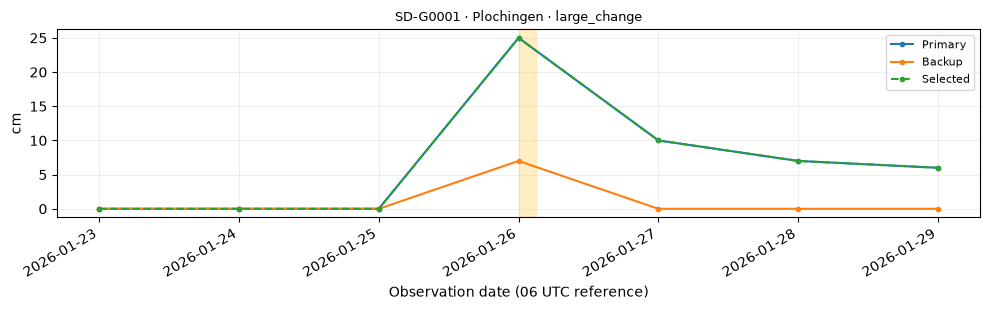

In [4]:
review_events = workflow.locate_review_candidates()
display(review_events.head(30))
workflow.show_context_examples(limit=8)
from snow_depth_review import apply_snow_depth_review, export_snow_depth_review, finalize_snow_depth_report
reviewed_snow_depth = apply_snow_depth_review(workflow)
print("Snow-depth review complete: retain current primary and mapping; values unchanged.")

## 5. Validate and export

Check unique keys, complete grids, identifiers, mapped distances, time metadata and source consistency. Compare study-period backup and remaining-gap counts with the saved mapping audit. Read the exported Parquet files back and compare their contents. Preserve initial values and review flags; save workflow rules, input/output hashes and audit tables.

These are station-observation tables, not journey-level features. Retrospective review flags and publication timestamps are not prediction-time features. Detailed instrument/site review and journey prediction-time matching remain separate work. The current primary/backup mapping is retained after project review of the comparison plots.

In [5]:
validation = workflow.validate_and_export()
display(validation)
print("Source and initial railway tables exported successfully.")
reviewed_path = export_snow_depth_review(workflow)

Source and initial railway tables exported successfully.
Reviewed snow_depth exported: 1 records retain primary; 0 pending; snow_depth values and sources unchanged.


,check,status
0,"Input archive hashes, station IDs, units and e...",passed
1,"Complete source and railway grids, including b...",passed
2,Unique station/time keys and string IDs,passed
3,Primary-first / same-time backup selection and...,passed
4,Saved mapping backup and gap counts for all ra...,passed
5,Parquet round-trip equality,passed
6,Anomaly-driven manual changes,none


## 6. Report

The consolidated report below covers source quality, primary/backup selection, screening, validation and outstanding decisions. It is also saved as a Markdown file for GitHub.

In [6]:
report = workflow.write_report()
report = finalize_snow_depth_report(workflow, report)
display(Markdown(report))

# Snow depth quality report

Input snapshot: 16 October 2026. Variable: `SHK_TAG`; unit: cm; frequency: daily.

## Status and scope

The raw observations have been standardized, primary/backup selection has been applied and the checks below have run. All 1 initial flagged study records have a recorded project decision to retain the primary observation. No study records await review under the current screening rules. Numeric snow_depth values and selected sources are unchanged; diagnostic flags are retained.

Study period: 2024-07-01 to 2026-10-01 exclusive. Reported counts exclude the preceding 48-hour buffer. Source observations cover 20 DWD stations; the railway selection covers 19 railway stations. Shared DWD values at different railway stations are not independent measurements.

## Results

| Measure | Count |
| --- | ---: |
| Original ZIPs verified against recorded SHA-256 | 40 |
| Source study station-days | 16,440 |
| Source usable positions | 16,415 |
| Source missing/unknown positions | 25 |
| Railway study station-days | 15,618 |
| Railway positions using primary | 15,609 |
| Railway positions using same-time backup | 9 |
| Railway remaining missing/unknown positions | 0 |
| Source unresolved same-priority value conflicts | 0 |
| Source historical/recent value differences | 0 |
| Invalid timestamp rows in original archives | 0 |
| Railway records flagged for review | 1 |

The source grid contains all mapped primary and backup stations. Missing source values can therefore remain even when the selected railway table has complete coverage.

## Rules and screening

`-999`, blanks and non-numeric/non-finite tokens cannot supply a value; raw tokens remain available. Historical rows take priority over recent overlaps, including missing historical rows. Conflicting values at the chosen archive priority are unavailable pending review. Select the primary first; select the same-time backup only if the primary cannot supply a usable observation. No interpolation or zero filling is used.

| check | value |
| --- | --- |
| Physical range | negative values flagged; retained (cm) |
| High value | > 50.0 cm |
| Adjacent-time absolute change | > 20.0 cm |
| Primary/backup absolute difference | > 30.0 cm |
| Identical positive run | >= 30 days |
| Zero runs | valid; no stuck-sensor flag |

Finite numeric candidates remain in the initial table. Screening thresholds are project review rules, not DWD standards or evidence that an observation is wrong. Differences between nearby stations may reflect local weather. Missing/unknown values are counted separately from numeric anomalies. Quality codes are preserved; a code change alone does not invalidate a value.

| check | source_records | railway_records |
| --- | --- | --- |
| large_change | 2 | 1 |

## Railway-station results

| railway_station | expected | primary_positions | backup_positions | missing_or_unknown | flagged_records | minimum | maximum |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Frankfurt (Main) Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 3 |
| München Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 15 |
| Frankfurt (Main) Süd | 822 | 822 | 0 | 0 | 0 | 0 | 3 |
| Hanau Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 3 |
| Aschaffenburg Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 15 |
| Würzburg Hbf | 822 | 821 | 1 | 0 | 0 | 0 | 21 |
| Fürth (Bay) Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 25 |
| Nürnberg Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 25 |
| Ingolstadt Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 18 |
| Bamberg | 822 | 817 | 5 | 0 | 0 | 0 | 25 |
| Mainz Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 3 |
| Darmstadt Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 3 |
| Mannheim Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 6 |
| Heidelberg Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 6 |
| Stuttgart Hbf | 822 | 820 | 2 | 0 | 0 | 0 | 10 |
| Plochingen | 822 | 822 | 0 | 0 | 1 | 0 | 25 |
| Ulm Hbf | 822 | 821 | 1 | 0 | 0 | 0 | 19 |
| Augsburg Hbf | 822 | 822 | 0 | 0 | 0 | 0 | 11 |
| München-Pasing | 822 | 822 | 0 | 0 | 0 | 0 | 15 |

## Review locations and supporting checks

- [Review event index and example charts](review_candidates.md); [all flagged records](review_records.csv); [all events](review_events.csv); [context values](review_context.parquet).
- [DWD station summary](source_station_summary.csv), [station × variable × month checks](source_monthly_quality.csv), [continuous source gaps](source_gap_runs.csv), [monthly quality-code counts](source_monthly_quality_codes.csv).
- [Railway monthly checks](railway_monthly_quality.csv), [remaining railway gaps](railway_gap_runs.csv), [screening counts](flag_summary.csv).
- [Archive overlap diagnostics](archive_overlap_diagnostics.csv), [unresolved duplicate records](unresolved_duplicate_records.csv), [metadata inventory and records](metadata_records.json).
- [Original archive URLs and hashes](archive_inventory.csv), [workflow rules and versions](workflow_manifest.json), [validation results](validation_checks.csv).

## Validation and remaining work

Archive hashes, effective metadata, complete grids, unique keys, station IDs, mapped distances and every selected value/provenance record passed automated checks. Backup and remaining-gap counts agree with the saved station-mapping audit for all 19 railway stations. Both Parquet files passed read-back equality checks.

Source flags and railway flags are retrospective audit fields, not model features. The recorded project review is applied to the separate reviewed railway table; the initial table preserves the original pending-review state. This review records source choices, not independent proof that every measurement is accurate. Instrument/geography metadata have been inventoried; detailed instrument/site interpretation, observation publication-time availability and journey prediction-time matching remain separate tasks.

## Outputs and sources

- [DWD observations](../../observations/snow_depth.parquet): DWD station ID plus observation date.
- [Initial railway observations](../../observations/railway_snow_depth_initial.parquet): railway EVA ID plus observation date; includes both candidate station values and selected-source provenance.
- Original provider: Deutscher Wetterdienst (DWD), Climate Data Center; [official dataset description](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/DESCRIPTION_obsgermany-climate-daily-kl_en.pdf). Exact ZIP URLs, download times and hashes are listed in the archive inventory. Parameter/time-reference metadata are read from the original ZIPs.

## Daily snow-depth timing

All mapped source metadata used here specify `06 UTC`. `observation_date` remains a date; `measurement_time_utc` records that date at 06:00 UTC. Neither field establishes when DWD published the observation. Backup selection uses the same date and compatible reference metadata. The table is not expanded to hourly values; prediction-time alignment must be decided during integration. Long zero runs are valid snow-free periods.

## Recorded snow_depth review

All 1 initial flagged records retain their mapped primary station under the recorded project decision. No snow-depth values, sources or quality codes changed. Diagnostic flags remain visible; outstanding study records: zero. Current snow-depth mapping is retained after reviewing station distances and nearby observations. The Plochingen observation remains 25 cm from DWD 02485; nearby Notzingen reports 21 cm. No nearest-available re-mapping has been applied.

Current input: [reviewed snow_depth table](../../observations/railway_snow_depth_reviewed.parquet). [Applied decisions](review_decisions.csv) and [decision registry](review_decisions.json) retain the review trail.
